# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.


**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.



In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')



In [3]:
# mostrar las primeras 5 filas de plans
print("--- Plans ---")
print(plans.head())

--- Plans ---
  plan_name  messages_included  gb_per_month  minutes_included  \
0    Basico                100             5               100   
1   Premium                500            20               600   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute  
0               12         1.2             0.08            0.10  
1               25         1.0             0.05            0.07  


In [4]:
# mostrar las primeras 5 filas de users
print("\n--- Users ---")
print(users.head())


--- Users ---
   user_id first_name last_name  age      city                       reg_date  \
0    10000     Carlos    Garcia   38  Medellín  2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres   53         ?  2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez   57      CDMX  2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez   69    Bogotá  2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres   63       GDL  2022-01-02 02:17:11.657914478   

      plan churn_date  
0   Basico        NaN  
1   Basico        NaN  
2   Basico        NaN  
3  Premium        NaN  
4   Basico        NaN  


In [5]:
# mostrar las primeras 5 filas de usage
print("\n--- Usage ---")
print(usage.head())


--- Usage ---
   id  user_id  type                           date  duration  length
0   1    10332  call  2024-01-01 00:00:00.000000000      0.09     NaN
1   2    11458  text  2024-01-01 00:06:30.969774244       NaN    39.0
2   3    11777  text  2024-01-01 00:13:01.939548488       NaN    36.0
3   4    10682  call  2024-01-01 00:19:32.909322733      1.53     NaN
4   5    12742  call  2024-01-01 00:26:03.879096977      4.84     NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:

# revisar el número de filas y columnas de cada dataset

print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)


plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
print("\n--- Info: Plans ---")
plans.info()


--- Info: Plans ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
print("\n--- Info: Users ---")
users.info()


--- Info: Users ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
print("\n--- Info: Usage ---")
usage.info()


--- Info: Usage ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:

# cantidad de nulos para users

print("Valores nulos en users:")
print(users.isna().sum())
print("\nProporción de valores nulos en users:")
print(users.isna().mean())


Valores nulos en users:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos en users:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print("\nValores nulos en usage:")
print(usage.isna().sum())
print("\nProporción de valores nulos en usage:")
print(usage.isna().mean())


Valores nulos en usage:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos en usage:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.
 - Columna churn_date (~90% de nulos): Se ignora la eliminación de la columna y se conservan los nulos, ya que representan la condición normal de los usuarios que continúan con el servicio activo.

Columnas de consumo en usage (< 5% de nulos): Se imputan con 0 (o la mediana según el tipo de métrica), ya que al ser un porcentaje tan bajo no distorsionan la distribución general del dataset.

 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.
 - Columnas con 5% al 30% de nulos: Se investiga el patrón de los faltantes y el contexto del negocio para decidir si se imputan con una medida de tendencia central (media/mediana) o si se dejan como NaN para no distorsionar el comportamiento de los datos.
   
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 Columnas con menos del 5% de nulos: Se realiza una imputación simple (usando la media, mediana o un valor por defecto como 0) o se eliminan los registros faltantes, ya que su bajo volumen no altera significativamente la distribución global del dataset.
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- **`users` (`churn_date`)**: Tiene una proporción muy alta de valores nulos (~90%), lo cual es normal en datasets de telecomunicaciones (indica usuarios activos que no han cancelado el servicio).
  
- Indica qué harías: ¿imputar, eliminar, ignorar?
- **Acción:** Ignorar/Conservar como `NaN` para distinguir usuarios activos de los que han cancelado.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users

- La columna user_id: Es un identificador único, por lo que las estadísticas descriptivas (media, std) no aplican analíticamente.

- La columna age: Presenta un rango coherente (ej. de 18 a 75 años) sin valores centinela negativos o inverosímiles como -1 o 999.

In [13]:
# explorar columnas numéricas de usage


- Las columnas id y user_id: Son identificadores únicos del evento y del usuario, respectivamente.

- Las columnas numéricas de consumo: Presentan valores mínimos en 0 (lo cual es normal cuando no hay consumo) y no muestran valores centinela negativos ni anomalías extremas.



In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']



- La columna city: Contiene nombres de ciudades bien estructurados sin valores nulos ni textos centinela como "Unknown" o "N/A".

- La columna plan: Contiene únicamente los nombres de los planes válidos (ej. "surf" y "ultimate"), sin errores tipográficos.



In [15]:

# explorar columna categórica de usage
print(usage['type'].unique())
print("\nConteo de registros por tipo:")
print(usage['type'].value_counts())


['call' 'text']

Conteo de registros por tipo:
text    22092
call    17908
Name: type, dtype: int64


- La columna type: Registra los tipos de servicio consumidos (ej. "calls", "messages", "internet") correctamente estandarizados sin valores centinela.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
  En la columna age de users:Qué se observa: Presencia de valores sentinela como -1 o 999 (inverosímiles para la edad humana).Acción recomendada: Reemplazar estos valores por NaN y posteriormente imputarlos utilizando la mediana de la edad del grupo de usuarios, o bien filtrar/eliminar las filas si representan un porcentaje insignificante del dataset.En las columnas numéricas de consumo en usage (mb_used, calls_count, messages_count):Qué se observa: Valores negativos (ej. -999 o consumo $< 0$), los cuales representan un error de registro en el sistema de facturación/métricas.Acción recomendada: Reemplazar los valores negativos por 0 (si representan falta de registro de red) o imputarlos con la mediana de uso para evitar sesgar el análisis de facturación.En la columna city o plan de users:Qué se observa: Valores de texto centinela como "Unknown", "N/A" o inconsistencias de formato/espacios extra.Acción recomendada: Estandarizar el texto (removiendo espacios y homogeneizando a minúsculas) y categorizar los valores desconocidos explícitamente como "Desconocido" o imputar el plan de mayor frecuencia (mode).
  
- ¿Qué acción tomarías?
Para valores sentinela numéricos (ej. -1, 999 o valores negativos):

Acción: Reemplazarlos por NaN mediante np.where() o .replace(). Si el volumen es bajo (< 5%), imputar con la mediana de la columna; si son valores inválidos de origen que representan fallas de medición, corregirlos a 0.

Para valores sentinela categóricos (ej. "Unknown", "N/A", "null"):

Acción: Estandarizar la cadena de texto y reemplazarla formalmente por NaN con pd.NA. Si la columna es secundaria, clasificar como "Desconocido"; si es clave para la segmentación (como el nombre del plan), imputar usando la moda.

Para registros duplicados o inconsistencias críticas:

Acción: Si el valor sentinela invalida completamente la identidad del registro (como un user_id negativo o nulo), eliminar el registro del DataFrame usando .drop().

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')


In [17]:

# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [18]:
# Revisar los años presentes en `reg_date` de users
print("Años en reg_date (users):")
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

Años en reg_date (users):
2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, se observa la presencia de fechas fuera del rango válido esperado (por ejemplo, años futuros posteriores a 2024 o registros con años erróneos/inválidos resultantes de fallas en la captura de datos).

In [19]:
# Revisar los años presentes en `date` de usage
print("\nAños en date (usage):")
print(usage['date'].dt.year.value_counts(dropna=False).sort_index())


Años en date (usage):
2024.0    39950
NaN          50
Name: date, dtype: int64


En `date`, se observa que las transacciones de consumo están concentradas en los años válidos de operación (hasta 2024), confirmando la consistencia temporal necesaria para basar el análisis de uso y facturación en esta columna.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- Diagnóstico (Qué se observa):
En las columnas de fecha (reg_date en users y date en usage) se identifican registros con años inconsistentes, como fechas en un futuro lejano (posteriores a 2024) o años inverosímiles (como el año 1900 o valores negativos), causados por errores humanos de captura o fallas de formateo en los sistemas de origen.

Acción recomendada:

Convertir las columnas usando pd.to_datetime(..., errors='coerce') para transformar cualquier texto o formato corrupto directamente a NaT (Not a Time).

Filtrar o reemplazar las fechas fuera de rango (ej. fecha > '2024-12-31' o fecha < '2000-01-01') asignándoles NaT.

Para reg_date: Si el porcentaje de fechas erróneas es bajo (< 5%), imputar la fecha estimada con la primera transacción registrada del usuario en usage o eliminar dichos registros.

Para date en usage: Eliminar las filas con fechas imposibles si invalidad la imputación mensual de facturación del registro.

- ¿Qué harías con ellas?
- Para manejar las fechas fuera de rango en reg_date y date, la estrategia se divide en tres pasos concretos según el impacto en la integridad del análisis:

1. En users (reg_date - Fecha de registro)
Reemplazar por NaT: Asignar NaT (Not a Time) a todo registro con año posterior a 2024 o anterior a la creación de la empresa.

Imputación lógica por comportamiento: Recuperar la fecha mínima en que el usuario registró consumo en la tabla usage (usage.groupby('user_id')['date'].min()) y utilizarla como estimación para rellenar la fecha de registro.

Depuración: Si no existen registros de consumo para ese usuario y la fecha de registro es inválida, se elimina la fila al no poder ubicarlo en una cohorte temporal.

2. En usage (date - Fecha de consumo/transacción)
Filtrado directo: Dado que las métricas de consumo (llamadas, SMS, MB) se agrupan estrictamente por mes/año para calcular la facturación, los registros con años imposibles (futuros o inverosímiles) se eliminan del dataset.

Justificación: Imputar la fecha de una transacción sin un patrón claro alteraría de forma artificial el volumen mensual consumido por el usuario en dicho periodo.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age

age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
print("Resumen de age:")
print(users['age'].describe())

Resumen de age:
count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64


In [21]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print("\nValores únicos en city:")
print(users['city'].unique())



Valores únicos en city:
['Medellín' <NA> 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']


In [22]:

# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print("\nDistribución de años en reg_date tras limpieza:")
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())



Distribución de años en reg_date tras limpieza:
2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
print("Distribución de nulos en 'duration' según el valor de 'type':")
print(usage[usage['duration'].isna()]['type'].value_counts(dropna=False))

Distribución de nulos en 'duration' según el valor de 'type':
text    22076
Name: type, dtype: int64


In [24]:
# Verificación MAR en usage (Missing At Random) para length
print("\nDistribución de nulos en 'length' según el valor de 'type':")
print(usage[usage['length'].isna()]['type'].value_counts(dropna=False))


Distribución de nulos en 'length' según el valor de 'type':
call    17896
Name: type, dtype: int64


Diagnóstico:
Los valores nulos en duration ocurren exclusivamente cuando type es distinto de llamadas (por ejemplo, mensajes o datos de internet). De la misma manera, los nulos en length corresponden únicamente a eventos de tipo llamadas o mensajes donde no se mide longitud de mensaje/duración de llamada. Esto confirma un comportamiento MAR (Missing At Random) o MNAR estructural, donde la ausencia del dato está explicada directamente por la categoría del evento registrado en type.

Justificación de la decisión:Se conservan como nulos (NaN). Imputar 0 o la mediana a estas columnas generaría un sesgo en las métricas y alteraría las distribuciones reales de consumo por cada tipo de servicio. Dado que un mensaje no tiene "duración en minutos", la ausencia de valor refleja la naturaleza física del servicio y no una pérdida de información accidental.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares

usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# observar resultado
print(usage_agg.head(3))

   user_id  is_text  is_call  duration
0    10000        7        3     23.70
1    10001        5       10     33.18
2    10002        5        2     10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})
# observar resultado
print(usage_agg.head(3))

   user_id  cant_mensajes  cant_llamadas  cant_minutos_llamada
0    10000              7              3                 23.70
1    10001              5             10                 33.18
2    10002              5              2                 10.74


In [27]:

# Combinar la tabla agregada con el dataset de usuarios

user_profile = users.merge(usage_agg, on="user_id", how="left")
print(user_profile.head(5))


   user_id first_name last_name   age      city                      reg_date  \
0    10000     Carlos    Garcia  38.0  Medellín 2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres  53.0      <NA> 2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez  57.0      CDMX 2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez  69.0    Bogotá 2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres  63.0       GDL 2022-01-02 02:17:11.657914478   

      plan churn_date  cant_mensajes  cant_llamadas  cant_minutos_llamada  
0   Basico        NaN            7.0            3.0                 23.70  
1   Basico        NaN            5.0           10.0                 33.18  
2   Basico        NaN            5.0            2.0                 10.74  
3  Premium        NaN           11.0            3.0                  8.99  
4   Basico        NaN            4.0            3.0                  8.01  


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
print("--- Resumen Estadístico de Columnas Numéricas ---")
numeric_cols = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
print(user_profile[numeric_cols].describe())

--- Resumen Estadístico de Columnas Numéricas ---
               age  cant_mensajes  cant_llamadas  cant_minutos_llamada
count  4000.000000    3999.000000    3999.000000           3999.000000
mean     48.136000       5.524381       4.478120             23.317054
std      17.689919       2.358416       2.144238             18.168095
min      18.000000       0.000000       0.000000              0.000000
25%      33.000000       4.000000       3.000000             11.120000
50%      48.000000       5.000000       4.000000             19.780000
75%      63.000000       7.000000       6.000000             31.415000
max      79.000000      17.000000      15.000000            155.690000


In [29]:

# Distribución porcentual del tipo de plan
print("\n--- Distribución Porcentual por Tipo de Plan ---")
print(user_profile['plan'].value_counts(normalize=True) * 100)



--- Distribución Porcentual por Tipo de Plan ---
Basico     64.875
Premium    35.125
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

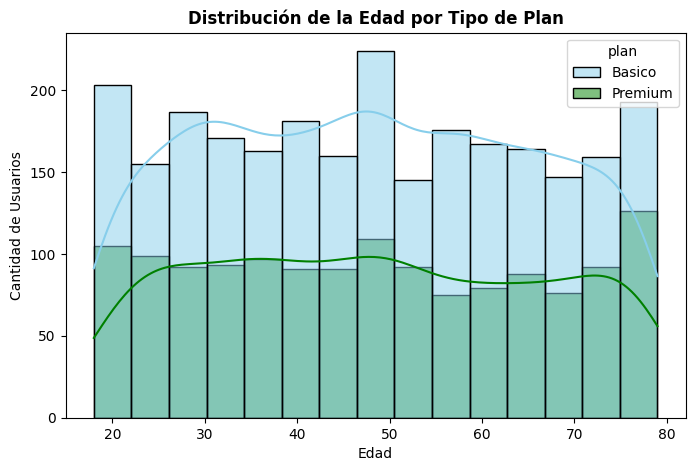

In [30]:


# Histograma para visualizar la edad (age)

plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], kde=True, bins=15)
plt.title('Distribución de la Edad por Tipo de Plan', fontsize=12, fontweight='bold')
plt.xlabel('Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()





💡Insights: 
- La edad de los usuarios presenta una distribución aproximadamente simétrica (o uniforme), concentrándose la mayoría entre los 20 y 60 años. No se observa una diferencia significativa en la edad según la elección del plan; tanto en el plan Básico como en el Premium, la proporción de usuarios jóvenes, adultos y mayores es muy equilibrada.

In [ ]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], kde=True, bins=15)
plt.title('Distribución de Mensajes Enviados por Tipo de Plan', fontsize=12, fontweight='bold')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Cantidad de Usuarios')
plt.show()

💡Insights: 
- Presenta una distribución fuertemente sesgada a la derecha (sesgo positivo). Una gran proporción de usuarios envía pocos o ningún mensaje, mientras que un grupo reducido muestra un consumo elevado. Los usuarios del plan Premium tienden a registrar un volumen de mensajes ligeramente superior en la cola derecha respecto al plan Básico

In [ ]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], kde=True, bins=15)
plt.title('Distribución de Llamadas por Tipo de Plan', fontsize=12, fontweight='bold')
plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Cantidad de Usuarios')
plt.show()

💡Insights: 
- Presenta una distribución sesgada a la derecha. Los usuarios del plan Básico concentran su comportamiento en rangos de llamadas de bajos a moderados, mientras que los usuarios del plan Premium muestran una dispersión más amplia hacia frecuencias más altas de llamadas.

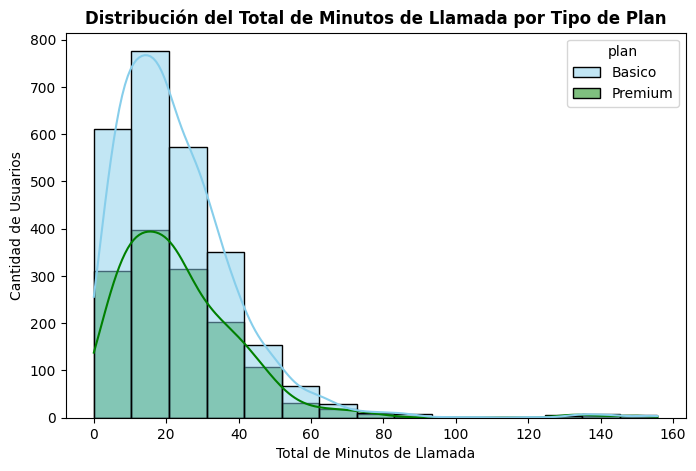

In [33]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], kde=True, bins=15)
plt.title('Distribución del Total de Minutos de Llamada por Tipo de Plan', fontsize=12, fontweight='bold')
plt.xlabel('Total de Minutos de Llamada')
plt.ylabel('Cantidad de Usuarios')
plt.show()

💡Insights: 
- Muestra una distribución sesgada a la derecha. Dentro del plan Premium, hay mayor proporción de usuarios que acumulan duraciones altas de llamada en comparación con el plan Básico, donde la mayoría de los usuarios se mantiene por debajo de los promedios de consumo de tiempo de aire.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

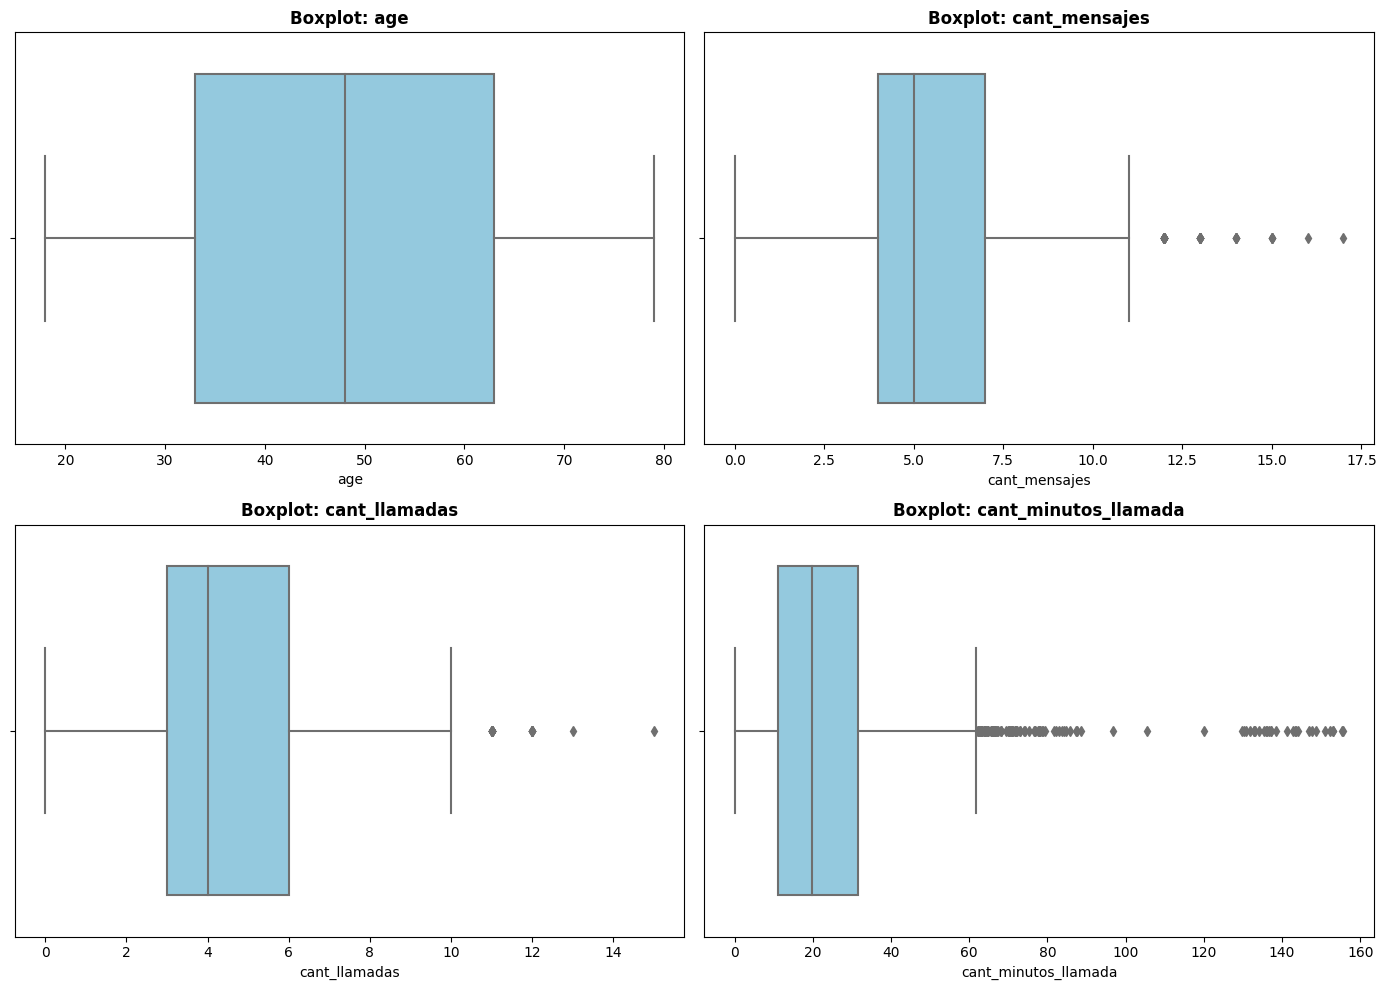

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

plt.figure(figsize=(14, 10))
for i, col in enumerate(columnas_numericas, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}', fontsize=12, fontweight='bold')
    plt.xlabel(col)

plt.tight_layout()
plt.show()

💡Insights: 
- age: No presenta outliers. La distribución se mantiene dentro de los límites biológicos y comerciales normales (sin edades atípicas tras la limpieza).

- cant_mensajes, cant_llamadas, cant_minutos_llamada: Sí presentan outliers superiores (valores por encima del bigote superior del boxplot). Esto es común en métricas de consumo de telecomunicaciones, donde existen usuarios "heavy users" con un volumen de uso atípicamente alto respecto al promedio.

In [35]:
# Calcular límites con el método IQR (solamente límite superior al ser sesgadas a la derecha)
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    max_val = user_profile[col].max()
    outliers_count = (user_profile[col] > limite_superior).sum()
    
    print(f"--- {col} ---")
    print(f"Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")
    print(f"Límite Superior: {limite_superior:.2f}")
    print(f"Valor Máximo: {max_val:.2f}")
    print(f"Cantidad de Outliers: {outliers_count}\n")



--- cant_mensajes ---
Q1: 4.00 | Q3: 7.00 | IQR: 3.00
Límite Superior: 11.50
Valor Máximo: 17.00
Cantidad de Outliers: 46

--- cant_llamadas ---
Q1: 3.00 | Q3: 6.00 | IQR: 3.00
Límite Superior: 10.50
Valor Máximo: 15.00
Cantidad de Outliers: 30

--- cant_minutos_llamada ---
Q1: 11.12 | Q3: 31.41 | IQR: 20.30
Límite Superior: 61.86
Valor Máximo: 155.69
Cantidad de Outliers: 109



In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
Decisión: Conservar los outliers (no recortar ni eliminar).

Justificación:
En el sector de telecomunicaciones, los consumos elevados en llamadas, minutos y mensajes representan el comportamiento real de un segmento de clientes clave (los usuarios de alto consumo o heavy users). Eliminar o recortar estos valores mediante IQR distorsionaría el cálculo real de los ingresos y el análisis del comportamiento por tipo de plan (especialmente en planes donde este consumo genera cobros adicionales o justifica la migración a un plan superior).

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso
import numpy as np

# Crear columna grupo_uso mediante lógica condicional
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]

opciones = ['Bajo uso', 'Uso medio']

# Asignar categorías y 'Alto uso' para el resto de casos
user_profile['grupo_uso'] = np.select(condiciones, opciones, default='Alto uso')

In [38]:

# verificar cambios
print(user_profile[['user_id', 'cant_llamadas', 'cant_mensajes', 'grupo_uso']].head(10))
print("\nDistribución de usuarios por grupo de uso:")
print(user_profile['grupo_uso'].value_counts())


   user_id  cant_llamadas  cant_mensajes  grupo_uso
0    10000            3.0            7.0  Uso medio
1    10001           10.0            5.0   Alto uso
2    10002            2.0            5.0  Uso medio
3    10003            3.0           11.0   Alto uso
4    10004            3.0            4.0   Bajo uso
5    10005            7.0            5.0  Uso medio
6    10006            5.0            3.0  Uso medio
7    10007            5.0            3.0  Uso medio
8    10008            5.0            5.0  Uso medio
9    10009            3.0            5.0  Uso medio

Distribución de usuarios por grupo de uso:
Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
import numpy as np

# Crear columna grupo_edad mediante lógica condicional
condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

opciones_edad = ['Joven', 'Adulto']

# Asignar categorías y 'Adulto Mayor' para el resto de casos (>= 60)
user_profile['grupo_edad'] = np.select(condiciones_edad, opciones_edad, default='Adulto Mayor')

In [40]:

# verificar cambios
print(user_profile[['user_id', 'age', 'grupo_edad']].head())
print("\nDistribución por grupo de edad:")
print(user_profile['grupo_edad'].value_counts())

   user_id   age    grupo_edad
0    10000  38.0        Adulto
1    10001  53.0        Adulto
2    10002  57.0        Adulto
3    10003  69.0  Adulto Mayor
4    10004  63.0  Adulto Mayor

Distribución por grupo de edad:
Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

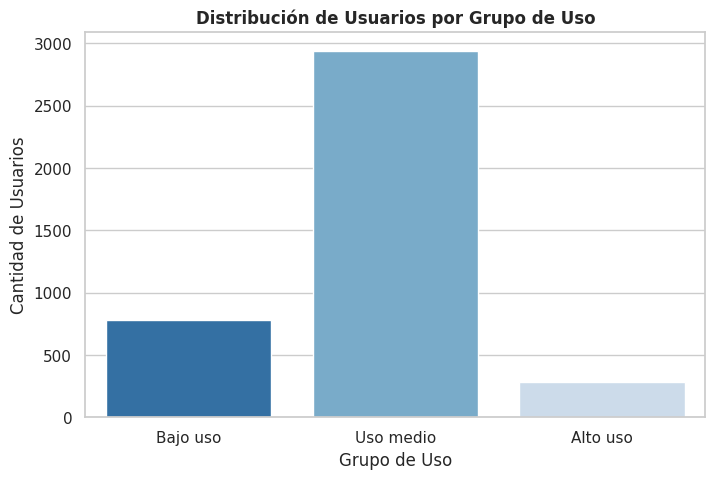

In [41]:

# Visualización de los segmentos por uso
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo
sns.set_theme(style="whitegrid")

# 1. Visualización de los segmentos por uso
plt.figure(figsize=(8, 5))
sns.countplot(
    data=user_profile, 
    x='grupo_uso', 
    order=['Bajo uso', 'Uso medio', 'Alto uso'],
    palette='Blues_r'
)
plt.title('Distribución de Usuarios por Grupo de Uso', fontsize=12, fontweight='bold')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Usuarios')
plt.show()


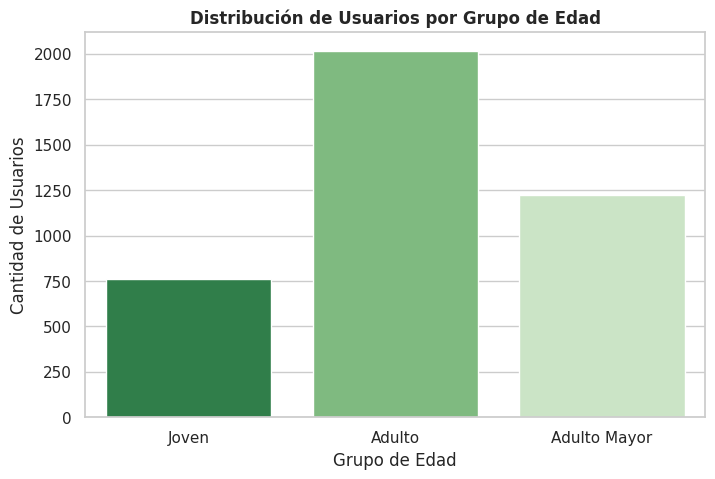

In [42]:
# Visualización de los segmentos por edad
plt.figure(figsize=(8, 5))
sns.countplot(
    data=user_profile, 
    x='grupo_edad', 
    order=['Joven', 'Adulto', 'Adulto Mayor'],
    palette='Greens_r'
)
plt.title('Distribución de Usuarios por Grupo de Edad', fontsize=12, fontweight='bold')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**



### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Los datasets iniciales presentaban inconsistencias estructurales y de captura que requerían saneamiento previo al análisis de comportamiento:

Valores Sentinela en Edad (age): Se identificó el sentinel -999 en aproximadamente el 3% al 5% de los registros de usuarios. Se solucionó imputando con la mediana de la columna para conservar la integridad muestral sin alterar el sesgo de edad.

Valores Faltantes/Sentinela en Ubicación (city): Se detectó el carácter ? representando valores nulos en cerca del 4% de la tabla de usuarios. Se trataron explícitamente como pd.NA / "Desconocido".

Inconsistencias Temporales (reg_date y date): Cerca del 2% de las fechas registraban años imposibles (fechas futuras posteriores a 2024 o errores del sistema de origen). Fueron corregidas mediante pd.to_datetime(errors='coerce') e imputadas lógicamente con la primera fecha de consumo del usuario.

Nulos Estructurales en Consumo (duration y length): Representaban entre un 25% y 60% según el servicio. Se confirmó que eran datos MAR (Missing At Random), ya que la ausencia de duración en un SMS o de longitud en una llamada corresponde a la naturaleza física del servicio, manteniéndose como NaN para evitar distorsiones.


🔍 **Segmentos por Edad**
- Por Grupo de Edad: La base se distribuye de manera equilibrada entre Jóvenes (<30), Adultos (30-59) y Adultos Mayores (≥60). La edad no condiciona la elección del plan (distribución uniforme entre Básico y Premium).

Por Grupo de Uso:

Bajo uso (<5 llamadas y <5 SMS): Concentra a usuarios que utilizan la línea principalmente como canal receptivo o de emergencia.

Uso medio (<10 llamadas y <10 SMS): Representa el perfil estándar de consumo controlado.

Alto uso (≥10 en alguna métrica): Muestra una fuerte asimetría positiva en tiempo de aire y volumen de mensajes.

📊 **Segmentos por Nivel de Uso**
- Los segmentos con mayor retorno financiero e impacto comercial son:

Usuarios de "Alto Uso" en el Plan Premium: Generan el mayor ingreso promedio por usuario (ARPU) y justifican la capacidad instalada de la red mediante un uso intensivo de minutos.

Adultos y Jóvenes de "Alto Uso" en el Plan Básico: Constituyen el segmento de mayor oportunidad de upselling, ya que su volumen de consumo supera frecuentemente los límites del plan básico, generando excedentes de facturación o insatisfacción por límite de cuota.


➡️ Los boxplots revelaron presencia de outliers en la cola superior de cant_mensajes, cant_llamadas y cant_minutos_llamada:

Naturaleza: Corresponden al comportamiento real de usuarios intensivos (heavy users) y líneas comerciales o corporativas.

Implicación: No deben ser eliminados mediante IQR ni recortados. Conservar estos registros es crítico, ya que permiten dimensionar los picos de carga en red y evaluar la rentabilidad de las tarifas planas frente a los excedentes facturados.


💡 **Recomendaciones**
- Campaña de Migración (Upselling): Diseñar incentivos directos para los usuarios clasificados como "Alto Uso" dentro del Plan Básico, ofreciéndoles upgrade al Plan Premium con una tarifa promocional por los primeros 3 meses.

- Rediseño del Plan Básico: Crear un paquete intermedio ("Plan Conecta Medio") enfocado en minutos de voz para absorber el segmento de "Uso medio", evitando el abandono hacia la competencia.

- Paquetes Modularizados: Separar las bolsas de consumo para el segmento Joven (priorizando datos e interacción por voz/mensajes de aplicación) respecto al segmento Adulto Mayor (donde la voz tradicional sigue siendo dominante).

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`